In [12]:
# 1. Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load the synthetic dataset
DATA_PATH = "../data/synthetic_pain_patients.csv"
df = pd.read_csv(DATA_PATH)

# 3. First look
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2000, 21)


,patient_id,mechanism,pain_duration_months,pain_distribution,dn4_score,paindetect_score,csi_score,sleep_quality,imaging_tissue_finding,imaging_nerve_compression,...,hads_depression,pcs_score,tsk_score,work_stress,rf_cancer_history,rf_systemic_signs,rf_cauda_equina,rf_inflammatory,any_red_flag,rf_imaging_serious
0,1,mixed,36.9,widespread,3.0,18.0,55.0,4,not_performed,not_performed,...,NaN,31.0,36.0,5,False,False,False,False,False,False
1,2,neuropathic,13.6,dermatomal,5.0,20.0,43.0,2,not_performed,not_performed,...,7.0,4.0,32.0,4,False,False,False,False,False,False
2,3,mixed,9.1,dermatomal,2.0,17.0,48.0,4,no,no,...,5.0,25.0,40.0,2,False,False,False,False,False,False
3,4,nociplastic,65.0,widespread,1.0,16.0,56.0,4,not_performed,not_performed,...,12.0,17.0,40.0,9,False,False,False,False,False,False
4,5,nociceptive,0.8,localized,2.0,4.0,24.0,4,yes,no,...,8.0,13.0,43.0,5,False,False,False,False,False,False


In [13]:
# Column names, non-missing counts and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 2000 non-null   int64  
 1   mechanism                  2000 non-null   str    
 2   pain_duration_months       2000 non-null   float64
 3   pain_distribution          2000 non-null   str    
 4   dn4_score                  1918 non-null   float64
 5   paindetect_score           1919 non-null   float64
 6   csi_score                  1756 non-null   float64
 7   sleep_quality              2000 non-null   int64  
 8   imaging_tissue_finding     2000 non-null   str    
 9   imaging_nerve_compression  2000 non-null   str    
 10  hads_anxiety               1904 non-null   float64
 11  hads_depression            1850 non-null   float64
 12  pcs_score                  1917 non-null   float64
 13  tsk_score                  1924 non-null   float64
 14  wor

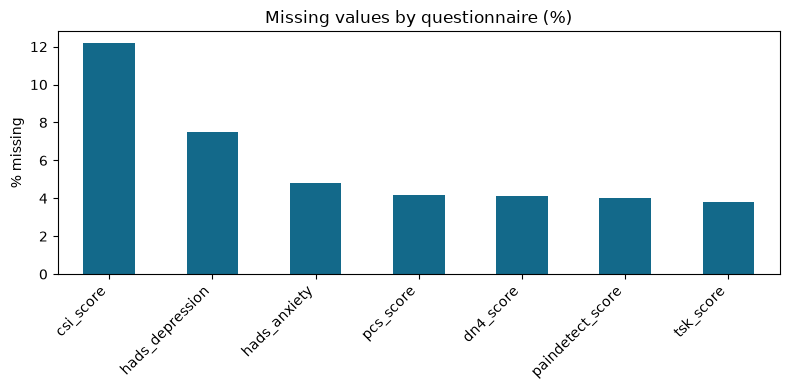

In [14]:
# % missing per column (only columns with missing values)
missing_pct = df.isna().mean().mul(100).round(1)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
missing_pct.plot(kind="bar", ax=ax, color="#13698A")
ax.set_title("Missing values by questionnaire (%)")
ax.set_ylabel("% missing")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
# % missing by mechanism: is missingness related to the class?
missing_cols = missing_pct.index.tolist()

(
    df[missing_cols]
    .isna()
    .groupby(df["mechanism"])
    .mean()
    .mul(100)
    .round(1)
)

,csi_score,hads_depression,hads_anxiety,pcs_score,dn4_score,paindetect_score,tsk_score
mechanism,,,,,,,
mixed,4.2,7.6,5.3,4.8,3.4,4.4,4.0
neuropathic,7.2,3.6,5.9,3.6,4.3,3.6,5.2
nociceptive,22.8,8.0,3.7,4.4,3.9,4.6,2.9
nociplastic,5.2,9.4,5.5,3.1,5.2,2.9,4.2


In [16]:
# Numeric clinical and questionnaire variables
numeric_cols = [
    "pain_duration_months", "dn4_score", "paindetect_score", "csi_score",
    "sleep_quality", "hads_anxiety", "hads_depression", "pcs_score",
    "tsk_score", "work_stress",
]

# Summary statistics (one row per variable)
df[numeric_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
pain_duration_months,2000.0,12.7,17.4,0.2,2.4,6.5,16.4,208.5
dn4_score,1918.0,3.0,2.0,0.0,1.0,3.0,4.0,10.0
paindetect_score,1919.0,13.5,7.1,-1.0,8.0,13.0,18.5,38.0
csi_score,1756.0,37.1,16.1,0.0,25.0,36.0,48.0,96.0
sleep_quality,2000.0,5.5,1.9,0.0,4.0,5.0,7.0,10.0
hads_anxiety,1904.0,7.4,3.6,0.0,5.0,7.0,10.0,17.0
hads_depression,1850.0,6.2,3.4,0.0,4.0,6.0,8.0,18.0
pcs_score,1917.0,19.2,10.1,0.0,12.0,19.0,26.0,52.0
tsk_score,1924.0,38.4,7.2,17.0,33.0,38.0,43.0,68.0
work_stress,2000.0,5.1,2.1,0.0,4.0,5.0,7.0,10.0


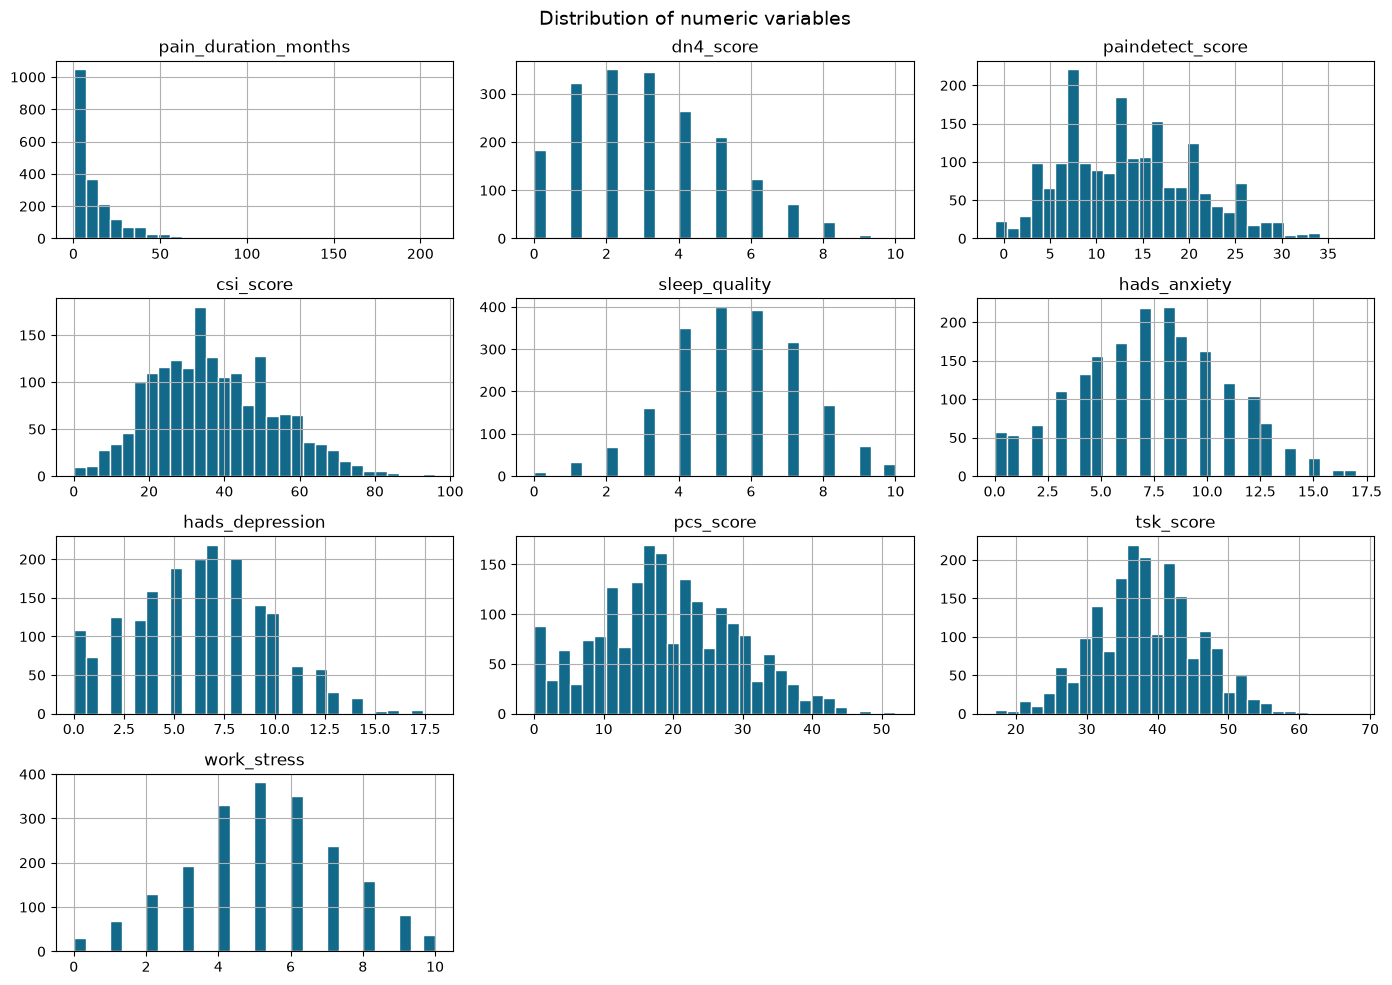

In [17]:
# Histograms: the shape of each distribution
df[numeric_cols].hist(bins=30, figsize=(14, 10), color="#13698A", edgecolor="white")
plt.suptitle("Distribution of numeric variables", fontsize=14)
plt.tight_layout()
plt.show()

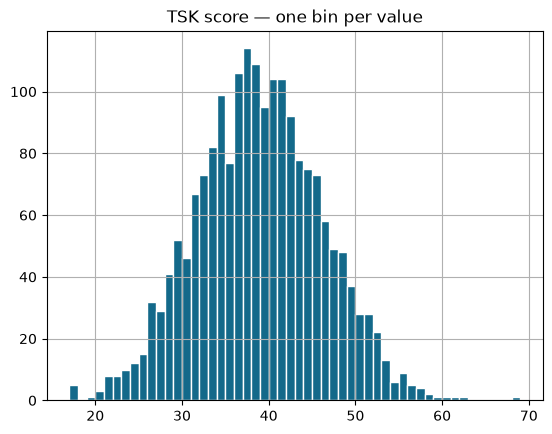

In [18]:
# TSK histogram with one bin per whole number (no binning artifact)
bins = range(17, 70)
df["tsk_score"].hist(bins=bins, color="#13698A", edgecolor="white")
plt.title("TSK score — one bin per value")
plt.show()

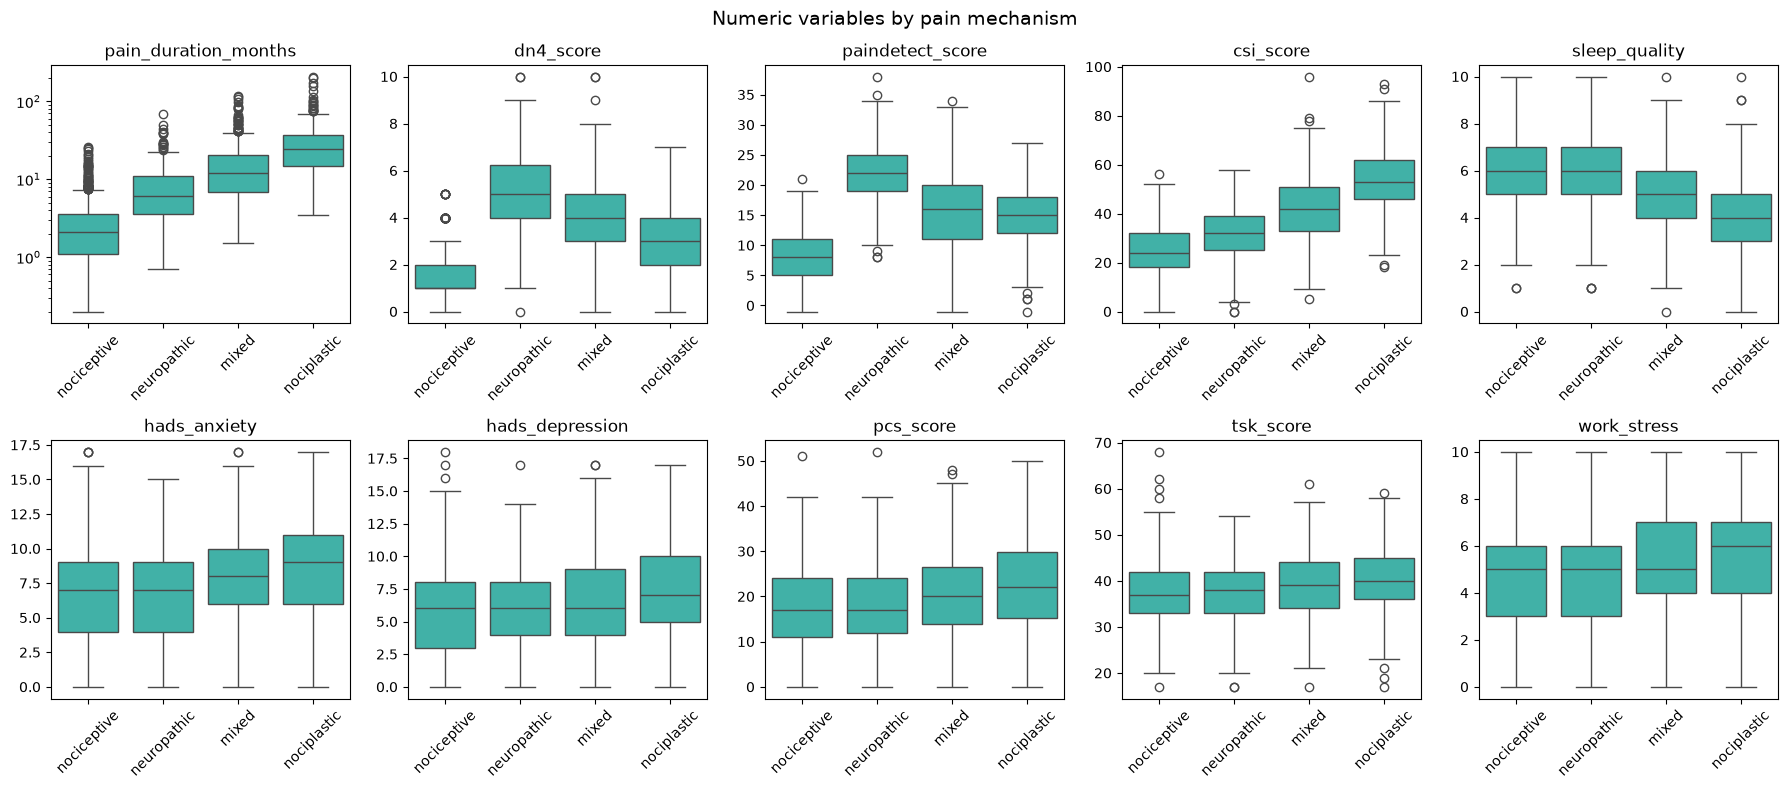

In [19]:
# Order of mechanisms for all plots (peripheral -> central)
MECHANISM_ORDER = ["nociceptive", "neuropathic", "mixed", "nociplastic"]

# Boxplots: compare each numeric variable across mechanisms
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(18, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(data=df, x="mechanism", y=col, order=MECHANISM_ORDER, ax=ax, color="#2EC4B6")
    if col == "pain_duration_months":
        ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Numeric variables by pain mechanism", fontsize=14)
plt.tight_layout()
plt.show()

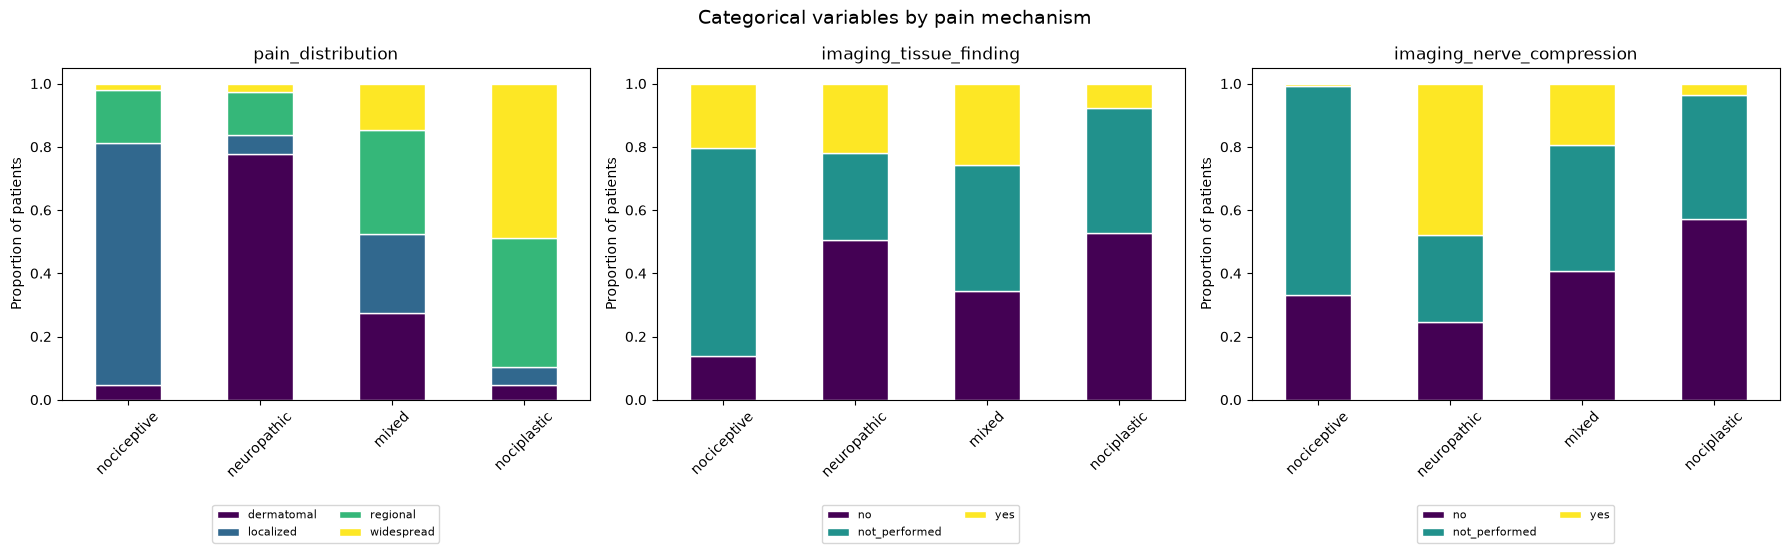

In [20]:
# Categorical variables: share of each category within each mechanism
categorical_cols = ["pain_distribution", "imaging_tissue_finding", "imaging_nerve_compression"]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

for ax, col in zip(axes, categorical_cols):
    table = pd.crosstab(df["mechanism"], df[col], normalize="index").loc[MECHANISM_ORDER]
    table.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion of patients")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)

plt.suptitle("Categorical variables by pain mechanism", fontsize=14)
plt.tight_layout()
plt.show()

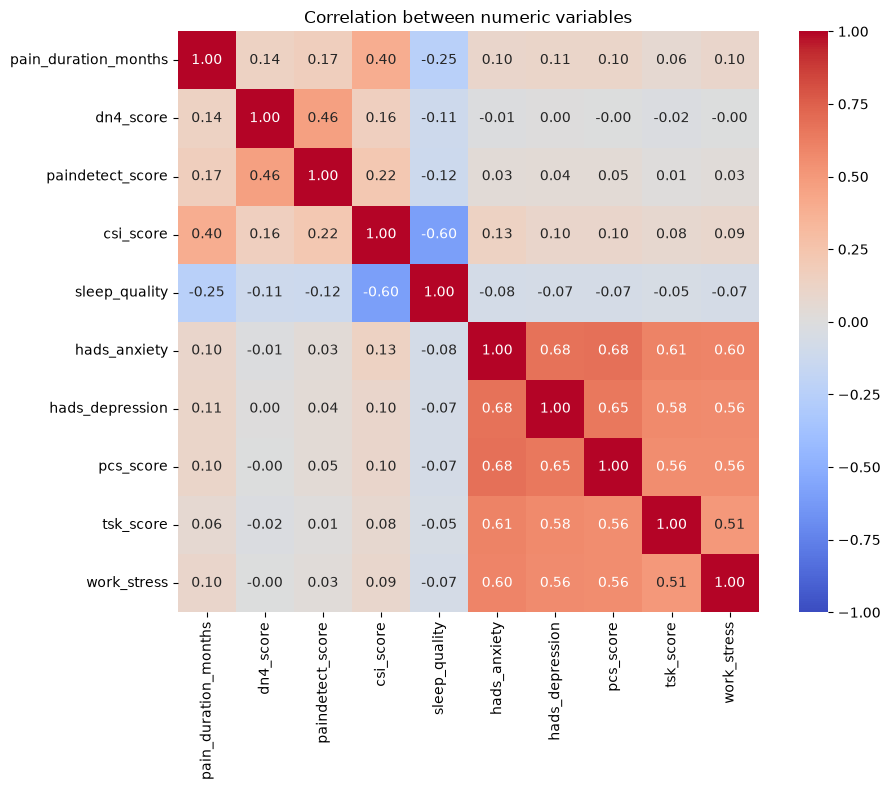

In [21]:
# Correlation heatmap of numeric variables
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
plt.show()